# Pipeline mimiSBM — descripteur par descripteur

Ce notebook a pour étapes : (`import` → `chargement des matrices d'adjacence` → `assemblage du tenseur A` → `estimation mimiSBM`) en utilisant la classe `MimiSBM` fournie.

**Différence avec `mimisbm_pipeline.ipynb` (version familles) :** chaque "vue" du tenseur `A` correspond ici à un **descripteur unique** (`Ka`, `Ka_SD`, `TE_Coverage_Mean`, ...) et non plus à une famille regroupant plusieurs colonnes. La structure du pipeline est identique à la version familles, seule la liste des vues change.

**Différences importantes avec la version R:**
- La classe Python ne gère que le cas **symétrique** (`SBM_sym`), pas `SBM` dirigé ni `LBM` biparti.
- Elle ne prend **qu'un seul couple (K, Q)** par appel — pas de recherche automatique sur plusieurs valeurs comme dans certaines variantes R.
- Il n'y a pas de paramètre `n_init` intégré : on reproduit ce comportement en relançant `fit()` manuellement plusieurs fois avec des `random_state` différents et en gardant le run au meilleur ELBO (exactement le rôle que jouait `n_init=10` côté R).
- Le critère de sélection de modèle est l'**ELBO** (pas d'ICL calculé nativement ici).

Dépendances nécessaires : `numpy`, `pandas`, `scipy`, `scikit-learn`, `fastkmeanspp`.
```
pip install numpy pandas scipy scikit-learn fastkmeanspp
```


## Imports

In [ ]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import pickle


# Importation de la classe MimiSBM depuis le fichier mimisbm-main/mimisbm/_model.py
from mimisbm_main.mimisbm._base import MimiSBM

## 1. Chargement des données

In [2]:
data_dir = Path(r"/mnt/c/Users/thoma/OneDrive/Documents/ENSIIE/Master/Stage 3A/Données")
python_adj_dir = data_dir / "adjacency" / "lda" 
plots_dir = Path(r"/mnt/c/Users/thoma/OneDrive/Documents/ENSIIE/Master/Stage 3A/Plots")
plots_dir.mkdir(parents=True, exist_ok=True)


## 2. Chargement des matrices d'adjacence

In [3]:
# Un descripteur = une vue du tenseur (au lieu d'une famille regroupant plusieurs colonnes)
descriptor_names = [
    "Ka",
    "PPI_Jaccard",
    "TE_Coverage_Asymmetry",
    "TE_Number_Asymmetry",
    "TE_Density_Asymmetry",
]

adj_dict = {}
for desc in descriptor_names:
    path = python_adj_dir / f"adjacency_matrix_bic_{desc}.csv"
    # index_col=0 retire la colonne d'index (equivalent au skip=1 + [, -1] du code R)
    adj = pd.read_csv(path, index_col=0).values

    unique_vals = np.unique(adj)
    print(f"[{desc}] Shape: {adj.shape[0]}x{adj.shape[1]}, "
          f"valeurs uniques: {sorted(unique_vals.tolist())}")

    if not np.all(np.isin(adj, [0, 1])):
        raise ValueError(f"Erreur : {desc} contient des valeurs differentes de 0 et 1")

    adj_dict[desc] = adj.astype(np.int64)


[Ka] Shape: 444x444, valeurs uniques: [0, 1]
[PPI_Jaccard] Shape: 444x444, valeurs uniques: [0, 1]
[TE_Coverage_Asymmetry] Shape: 444x444, valeurs uniques: [0, 1]
[TE_Number_Asymmetry] Shape: 444x444, valeurs uniques: [0, 1]
[TE_Density_Asymmetry] Shape: 444x444, valeurs uniques: [0, 1]


## 3. Assemblage et vérifications du tenseur A (N x N x V)

Diagonale mise à 0, symétrisation de sécurité si besoin,
puis vérifications (carré, dimensions cohérentes, symétrie, diagonale nulle).


In [4]:
N = adj_dict[descriptor_names[0]].shape[0]
V = len(descriptor_names)
print(f"Nombre d'individus : {N}, Nombre de descripteurs: {V}")

assert all(adj_dict[desc].shape[0] == N for desc in descriptor_names)
assert all(adj_dict[desc].shape[1] == N for desc in descriptor_names)

A = np.zeros((N, N, V), dtype=np.int64)
for i, desc in enumerate(descriptor_names):
    adj = adj_dict[desc].copy()
    np.fill_diagonal(adj, 0)  # pas d'auto-boucle
    if not np.array_equal(adj, adj.T):
        print(f"Le descripteur {desc} n'est pas symétrique")
        adj = np.maximum(adj, adj.T)  # symetrisation de securite
    A[:, :, i] = adj

assert A.shape == (N, N, V)
assert all(np.array_equal(A[:, :, v], A[:, :, v].T) for v in range(V))
assert all(np.all(np.diag(A[:, :, v]) == 0) for v in range(V))

tensor_path = plots_dir / "adjacency_tensor_bic.npy"
np.save(tensor_path, A)
print(f"Tenseur A sauvegarde : {tensor_path}")


Nombre d'individus : 444, Nombre de descripteurs: 5
Tenseur A sauvegarde : /mnt/c/Users/thoma/OneDrive/Documents/ENSIIE/Master/Stage 3A/Plots/adjacency_tensor_bic.npy


## 4. Estimation mimiSBM (multi-run, équivalent de `n_init = 10` en R)

La classe Python n'a pas de paramètre `n_init` intégré (contrairement à la fonction
R `mimiSBM()`). On reproduit donc plusieurs initialisations aléatoires indépendantes, on garde le run qui atteint le meilleur ELBO.

In [15]:
K_set = 2  # nombre de clusters d'individus a tester
Q_set = 2  # nombre de composantes de vues a tester
N_INIT = 10

best_model = None
best_elbo = -np.inf
previous_elbo = None
elbo_values = []

for run in range(1, N_INIT + 1):
    model = MimiSBM(
        n_clusters=K_set,
        n_components=Q_set,
        clusters_prior="jeffreys",
        components_prior="jeffreys",
        adjacency_prior="jeffreys",
        max_iter=100,
        tol=1e-4,
        random_state=None,  # graine differente a chaque run, comme les 10 runs R
    )
    model.fit(A)
    current_elbo = model.elbo_
    print(f"------------ Run {run} ------------")
    print(f"Evidence Lower Bound: {current_elbo:.2f}  (converged={model.converged_})")

    # On conserve le meilleur modele parmi tous les runs effectues.
    if current_elbo > best_elbo:
        best_elbo = current_elbo
        best_model = model

        
    elbo_values.append(current_elbo)
    previous_elbo = current_elbo

print()
print(f"Meilleur run retenu pour run {best_model.random_state}: ELBO = {best_elbo:.2f}")


------------ Run 1 ------------
Evidence Lower Bound: -256654.71  (converged=True)
------------ Run 2 ------------
Evidence Lower Bound: -256654.71  (converged=True)
------------ Run 3 ------------
Evidence Lower Bound: -256654.71  (converged=True)
------------ Run 4 ------------
Evidence Lower Bound: -256654.71  (converged=True)
------------ Run 5 ------------
Evidence Lower Bound: -256654.71  (converged=True)
------------ Run 6 ------------
Evidence Lower Bound: -256654.71  (converged=True)
------------ Run 7 ------------
Evidence Lower Bound: -256654.71  (converged=True)
------------ Run 8 ------------
Evidence Lower Bound: -256654.71  (converged=True)
------------ Run 9 ------------
Evidence Lower Bound: -256654.71  (converged=True)
------------ Run 10 ------------
Evidence Lower Bound: -256654.71  (converged=True)

Meilleur run retenu pour run None: ELBO = -256654.71


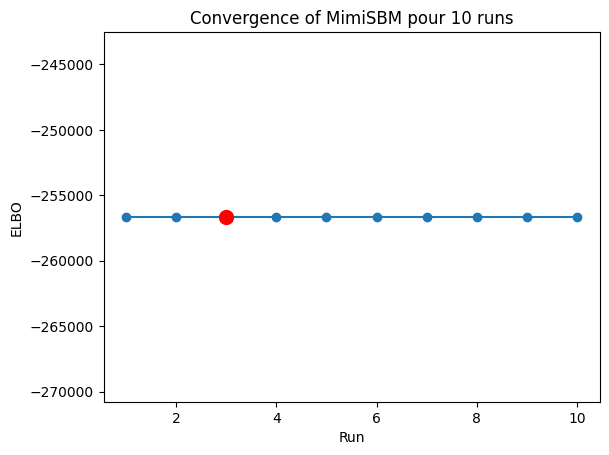

In [16]:
# faire une visualisation des valeurs de l'elbo selon le run, pour voir si on a atteint un plateau ou pas
import matplotlib.pyplot as plt

plt.plot(range(1, N_INIT + 1), elbo_values, marker='o')
# Mettre en evidence le meilleur run
best_run_index = elbo_values.index(best_elbo)
plt.plot(best_run_index + 1, best_elbo, marker='o', color='red', markersize=10)

plt.xlabel('Run')
plt.ylabel('ELBO')
plt.title(f'Convergence of MimiSBM pour {N_INIT} runs')
plt.show()

## 5. Résultats

Équivalent du bloc R final : extraction des clusters d'individus, des composantes de vues, tailles de clusters.

In [7]:
node_clusters, view_components = best_model.predict()

print("Tailles des clusters d'individus (K):")
print(pd.Series(node_clusters).value_counts().sort_index())

print()
print("Composante de vue retenue par descripteur:")
print(pd.DataFrame({"vue": descriptor_names, "composante": view_components[:len(descriptor_names)]}))


Tailles des clusters d'individus (K):
0    121
1    323
Name: count, dtype: int64

Composante de vue retenue par descripteur:
                     vue  composante
0                     Ka           1
1            PPI_Jaccard           0
2  TE_Coverage_Asymmetry           0
3    TE_Number_Asymmetry           0
4   TE_Density_Asymmetry           1


In [8]:
model_path = plots_dir / "mimiSBM_model_bic.pkl"
with open(model_path, "wb") as f:
    pickle.dump(best_model, f)

print(f"Modele mimiSBM sauvegarde : {model_path}")


Modele mimiSBM sauvegarde : /mnt/c/Users/thoma/OneDrive/Documents/ENSIIE/Master/Stage 3A/Plots/mimiSBM_model_bic.pkl


In [17]:
# boucle sur K et sur Q pour trouver le meilleur couple (K, Q) selon l'ELBO
best_model = None
best_elbo = -np.inf
for K in range(2, 11):  # K de 2 a 10
    for Q in range(1, 6):  # Q de 1 a 5
        model = MimiSBM(
            n_clusters=K,
            n_components=Q,
            clusters_prior="jeffreys",
            components_prior="jeffreys",
            adjacency_prior="jeffreys",
            max_iter=100,
            tol=1e-4,
            random_state=None,
        )
        model.fit(A)

        if model.elbo_ > best_elbo:
            best_elbo = model.elbo_
            best_model = model

        print(f"K={K}, Q={Q} : ELBO = {best_elbo:.2f}")

print(f"K={K}, Q={Q} : ELBO = {best_elbo:.2f}")
node_clusters, view_components = best_model.predict()

print(f"Tailles des clusters d'individus (K = {K}):")
print(pd.Series(node_clusters).value_counts().sort_index())

print()
print("Composante de vue retenue par descripteur:")
print(pd.DataFrame({"vue": descriptor_names, "composante": view_components[:len(descriptor_names)]}))

# printer responsibilities du model pour chaque composante de vue
print("Responsibilities du model pour chaque composante de vue:")
print(best_model.component_responsibilities_)

# print uniq de composantes de vue retenues
print("Composantes de vue retenues (uniques):")
print(np.unique(view_components[:len(descriptor_names)]))

print("Clusters uniques d'individus (K):")
print(np.unique(node_clusters))

K=2, Q=1 : ELBO = -308219.89
K=2, Q=2 : ELBO = -256654.71
K=2, Q=3 : ELBO = -225092.76
K=2, Q=4 : ELBO = -225092.76
K=2, Q=5 : ELBO = -223059.47
K=3, Q=1 : ELBO = -223059.47
K=3, Q=2 : ELBO = -223059.47
K=3, Q=3 : ELBO = -212716.04
K=3, Q=4 : ELBO = -195452.60
K=3, Q=5 : ELBO = -189515.78
K=4, Q=1 : ELBO = -189515.78
K=4, Q=2 : ELBO = -189515.78
K=4, Q=3 : ELBO = -189515.78
K=4, Q=4 : ELBO = -167577.53
K=4, Q=5 : ELBO = -167577.53
K=5, Q=1 : ELBO = -167577.53
K=5, Q=2 : ELBO = -167577.53
K=5, Q=3 : ELBO = -160732.71
K=5, Q=4 : ELBO = -142870.96
K=5, Q=5 : ELBO = -137692.26
K=6, Q=1 : ELBO = -137692.26
K=6, Q=2 : ELBO = -137692.26
K=6, Q=3 : ELBO = -137692.26
K=6, Q=4 : ELBO = -137692.26
K=6, Q=5 : ELBO = -115501.35
K=7, Q=1 : ELBO = -115501.35
K=7, Q=2 : ELBO = -115501.35
K=7, Q=3 : ELBO = -115501.35
K=7, Q=4 : ELBO = -115501.35
K=7, Q=5 : ELBO = -108433.17
K=8, Q=1 : ELBO = -108433.17
K=8, Q=2 : ELBO = -108433.17
K=8, Q=3 : ELBO = -108433.17
K=8, Q=4 : ELBO = -108433.17
K=8, Q=5 : ELB

In [10]:
# boucle sur K et sur Q pour trouver le meilleur couple (K, Q) selon l'ELBO
best_model = None
best_elbo = -np.inf
for K in range(2, 11):  # K de 2 a 10
    for Q in range(1, 6):  # Q de 1 a 5
        for run in range(1, N_INIT + 1):
            model = MimiSBM(
                n_clusters=K,
                n_components=Q,
                clusters_prior="jeffreys",
                components_prior="jeffreys",
                adjacency_prior="jeffreys",
                max_iter=100,
                tol=1e-4,
                random_state=None,
            )
            model.fit(A)

            if model.elbo_ > best_elbo:
                best_elbo = model.elbo_
                best_model = model

        print(f"Meilleur run retenu - K={K}, Q={Q} : ELBO = {best_elbo:.2f}")
        node_clusters, view_components = best_model.predict()

        print(f"Tailles des clusters d'individus (K = {K}):")
        print(pd.Series(node_clusters).value_counts().sort_index())

        print()
        print("Composante de vue retenue par descripteur:")
        print(pd.DataFrame({"vue": descriptor_names, "composante": view_components[:len(descriptor_names)]}))

        # printer responsibilities du model pour chaque composante de vue
        print("Responsibilities du model pour chaque composante de vue:")
        print(best_model.component_responsibilities_)

        # print uniq de composantes de vue retenues
        print("Composantes de vue retenues (uniques):")
        print(np.unique(view_components[:len(descriptor_names)]))

        print("Clusters uniques d'individus (K):")
        print(np.unique(node_clusters))


Meilleur run retenu - K=2, Q=1 : ELBO = -308219.89
Tailles des clusters d'individus (K = 2):
0    325
1    119
Name: count, dtype: int64

Composante de vue retenue par descripteur:
                     vue  composante
0                     Ka           0
1            PPI_Jaccard           0
2  TE_Coverage_Asymmetry           0
3    TE_Number_Asymmetry           0
4   TE_Density_Asymmetry           0
Responsibilities du model pour chaque composante de vue:
[[1.]
 [1.]
 [1.]
 [1.]
 [1.]]
Composantes de vue retenues (uniques):
[0]
Clusters uniques d'individus (K):
[0 1]
Meilleur run retenu - K=2, Q=2 : ELBO = -256654.71
Tailles des clusters d'individus (K = 2):
0    121
1    323
Name: count, dtype: int64

Composante de vue retenue par descripteur:
                     vue  composante
0                     Ka           1
1            PPI_Jaccard           0
2  TE_Coverage_Asymmetry           0
3    TE_Number_Asymmetry           0
4   TE_Density_Asymmetry           1
Responsibilities du mod

In [11]:
# Récupération du K et du Q optimaux à partir du meilleur modèle selon l'ELBO
optimal_K = best_model.n_clusters
optimal_Q = best_model.n_components

print(f"Meilleur couple (K,Q) selon l'ELBO : K = {optimal_K}, Q = {optimal_Q}")
print(f"Valeur ELBO : {best_elbo:.2e}")

Meilleur couple (K,Q) selon l'ELBO : K = 10, Q = 5
Valeur ELBO : -7.32e+04


### Autre version

In [ ]:
# Recherche des modèles et stockage de l'ELBO par couple (K, Q)
elbo_by_kq = {}
best_model = None
best_elbo = -np.inf
best_K = None
best_Q = None

for K in range(2, 11):
    for Q in range(1, 6):

        best_elbo_kq = -np.inf

        for run in range(1, N_INIT + 1):
            model = MimiSBM(
                n_clusters=K,
                n_components=Q,
                clusters_prior="jeffreys",
                components_prior="jeffreys",
                adjacency_prior="jeffreys",
                max_iter=100,
                tol=1e-4,
                random_state=run,
            )

            model.fit(A)

            if model.elbo_ > best_elbo_kq:
                best_elbo_kq = model.elbo_

            if model.elbo_ > best_elbo:
                best_elbo = model.elbo_
                best_model = model
                best_K = K
                best_Q = Q

        # Meilleur ELBO parmi les différentes initialisations pour ce couple
        elbo_by_kq[(K, Q)] = best_elbo_kq

        print(f"K={K}, Q={Q} : meilleur ELBO = {best_elbo_kq:.2f}")

print()
print(f"Meilleur couple global : K={best_K}, Q={best_Q}")
print(f"Meilleur ELBO global : {best_elbo:.2f}")

K=2, Q=1 : meilleur ELBO = -308219.89
K=2, Q=2 : meilleur ELBO = -256654.71
K=2, Q=3 : meilleur ELBO = -225092.76
K=2, Q=4 : meilleur ELBO = -229149.14
K=2, Q=5 : meilleur ELBO = -223059.47
K=3, Q=1 : meilleur ELBO = -301485.40
K=3, Q=2 : meilleur ELBO = -233539.83
K=3, Q=3 : meilleur ELBO = -202398.82
K=3, Q=4 : meilleur ELBO = -195452.60
K=3, Q=5 : meilleur ELBO = -175008.57
K=4, Q=1 : meilleur ELBO = -296592.98
K=4, Q=2 : meilleur ELBO = -225036.32
K=4, Q=3 : meilleur ELBO = -189859.72
K=4, Q=4 : meilleur ELBO = -163523.03
K=4, Q=5 : meilleur ELBO = -158337.69
K=5, Q=1 : meilleur ELBO = -292945.44
K=5, Q=2 : meilleur ELBO = -215786.39
K=5, Q=3 : meilleur ELBO = -160732.71
K=5, Q=4 : meilleur ELBO = -142870.96
K=5, Q=5 : meilleur ELBO = -136493.37
K=6, Q=1 : meilleur ELBO = -290318.57
K=6, Q=2 : meilleur ELBO = -210374.83
K=6, Q=3 : meilleur ELBO = -140133.74
K=6, Q=4 : meilleur ELBO = -122170.51
K=6, Q=5 : meilleur ELBO = -116178.23
K=7, Q=1 : meilleur ELBO = -289196.80
K=7, Q=2 : m

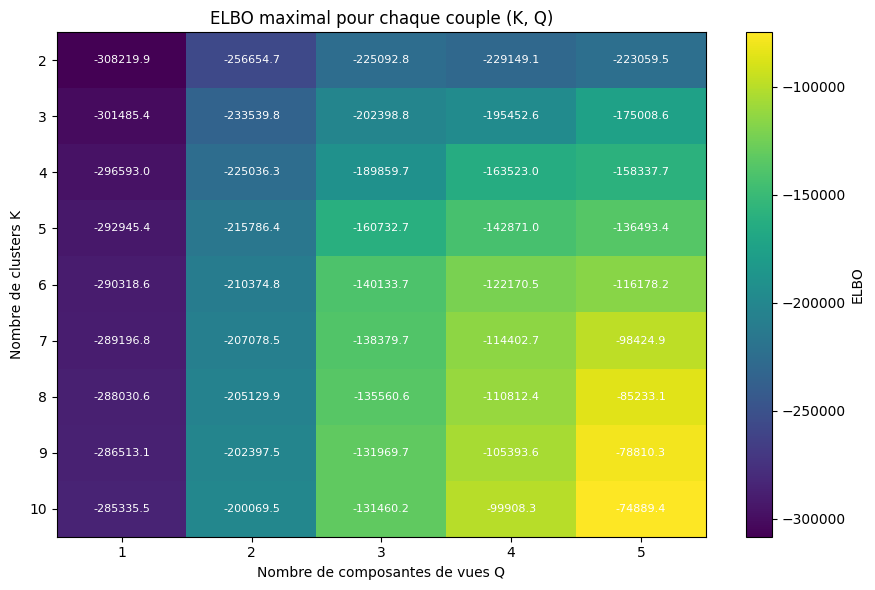

In [18]:
# Conversion en DataFrame
elbo_df = pd.DataFrame(
    [
        {"K": K, "Q": Q, "ELBO": elbo}
        for (K, Q), elbo in elbo_by_kq.items()
    ]
).sort_values(["K", "Q"])

# display(elbo_df)

# Tableau croisé K x Q
elbo_matrix = elbo_df.pivot(
    index="K",
    columns="Q",
    values="ELBO"
)

# display(elbo_matrix)

# Heatmap
plt.figure(figsize=(9, 6))

plt.imshow(
    elbo_matrix.values,
    aspect="auto",
    cmap="viridis"
)

plt.xticks(
    range(len(elbo_matrix.columns)),
    elbo_matrix.columns
)

plt.yticks(
    range(len(elbo_matrix.index)),
    elbo_matrix.index
)

plt.xlabel("Nombre de composantes de vues Q")
plt.ylabel("Nombre de clusters K")
plt.title("ELBO maximal pour chaque couple (K, Q)")

for i in range(elbo_matrix.shape[0]):
    for j in range(elbo_matrix.shape[1]):
        plt.text(
            j,
            i,
            f"{elbo_matrix.iloc[i, j]:.1f}",
            ha="center",
            va="center",
            color="white",
            fontsize=8
        )

plt.colorbar(label="ELBO")
plt.tight_layout()
plt.show()

In [19]:
elbo_df.sort_values(
    by="ELBO",
    ascending=False
).reset_index(drop=True)

,K,Q,ELBO
0,10,5,-74889.359146
1,9,5,-78810.324536
2,8,5,-85233.137415
3,7,5,-98424.884362
4,10,4,-99908.294081
5,9,4,-105393.596525
6,8,4,-110812.372027
7,7,4,-114402.721539
8,6,5,-116178.226965
9,6,4,-122170.513274


### Autre version sans run

In [20]:
# Recherche des modèles et stockage de l'ELBO par couple (K, Q)
elbo_by_kq = {}
best_model = None
best_elbo = -np.inf
best_K = None
best_Q = None

for K in range(2, 11):
    for Q in range(1, 6):

        best_elbo_kq = -np.inf

        model = MimiSBM(
            n_clusters=K,
            n_components=Q,
            clusters_prior="jeffreys",
            components_prior="jeffreys",
            adjacency_prior="jeffreys",
            max_iter=100,
            tol=1e-4,
            random_state=None,
        )

        model.fit(A)

        if model.elbo_ > best_elbo_kq:
            best_elbo_kq = model.elbo_

        if model.elbo_ > best_elbo:
            best_elbo = model.elbo_
            best_model = model
            best_K = K
            best_Q = Q

        # Meilleur ELBO parmi les différentes initialisations pour ce couple
        elbo_by_kq[(K, Q)] = best_elbo_kq

        print(f"K={K}, Q={Q} : meilleur ELBO = {best_elbo_kq:.2f}")

print()
print(f"Meilleur couple global : K={best_K}, Q={best_Q}")
print(f"Meilleur ELBO global : {best_elbo:.2f}")

K=2, Q=1 : meilleur ELBO = -308219.89
K=2, Q=2 : meilleur ELBO = -256654.71
K=2, Q=3 : meilleur ELBO = -225092.76
K=2, Q=4 : meilleur ELBO = -229149.14
K=2, Q=5 : meilleur ELBO = -223059.47
K=3, Q=1 : meilleur ELBO = -302708.48
K=3, Q=2 : meilleur ELBO = -242456.36
K=3, Q=3 : meilleur ELBO = -189337.27
K=3, Q=4 : meilleur ELBO = -190145.10
K=3, Q=5 : meilleur ELBO = -189515.78
K=4, Q=1 : meilleur ELBO = -296592.98
K=4, Q=2 : meilleur ELBO = -232293.33
K=4, Q=3 : meilleur ELBO = -189859.72
K=4, Q=4 : meilleur ELBO = -167577.53
K=4, Q=5 : meilleur ELBO = -178719.97
K=5, Q=1 : meilleur ELBO = -292945.44
K=5, Q=2 : meilleur ELBO = -215786.39
K=5, Q=3 : meilleur ELBO = -193177.69
K=5, Q=4 : meilleur ELBO = -142870.96
K=5, Q=5 : meilleur ELBO = -149968.83
K=6, Q=1 : meilleur ELBO = -290318.57
K=6, Q=2 : meilleur ELBO = -213760.35
K=6, Q=3 : meilleur ELBO = -202874.44
K=6, Q=4 : meilleur ELBO = -143545.68
K=6, Q=5 : meilleur ELBO = -146617.69
K=7, Q=1 : meilleur ELBO = -289277.71
K=7, Q=2 : m

## 6. Points d'attention (Python vs R)

- **Symétrie forcée** : `_validate_A` force `A |= A.swapaxes(0, 1)` et caste en booléen —
  toute pondération/poids continu serait perdu. Si tes matrices Python sont déjà 0/1
  symétriques (ce qui est le cas ici), ce n'est pas un problème.
- **Pas de recherche automatique de K/Q** : contrairement à la question du collapse
  observé côté R (K=4,Q=2 demandés → K=2,Q=1 effectifs), la version Python ne renvoie
  jamais moins de clusters que demandé — les `cluster_responsibilities_`/
  `component_responsibilities_` restent de taille (N, K) et (V, Q) fixes. Il est donc
  utile de comparer les tailles de clusters (`value_counts` ci-dessus) : un cluster
  quasi vide est le signe Python du même phénomène de collapse observé en R.
- **`n_init` manuel** : si tu veux paralléliser les runs (comme `nbCores` côté R), tu
  peux remplacer la boucle `for run in range(...)` par `joblib.Parallel`.
- **Nombre de vues (V)** : en passant de 4 familles à N descripteurs individuels, `V`
  augmente (autant de vues que de descripteurs retenus dans `descriptor_names`). Pense
  à revérifier la borne haute de `Q` dans la recherche en grille de la section 4 bis :
  avec beaucoup plus de vues, il peut être pertinent de tester des `Q` plus élevés
  qu'avec seulement 4 familles.
